# IAU – Phase 1: Exploratory Data Analysis
## Rail APU Predictive Maintenance – Dataset 012
**Authors:** Tereshchenko Mykhailo and Vladislav Chytnitskiy
**Contribution:** Tereshchenko Mykhailo – **50%**; Vladislav Chytynskyi – **50%**.

The goal is to explore the data, prepare an integrated dataset and investigate two hypotheses related to Failure. This phase covers data auditing, descriptive analysis, initial cleaning and statistical testing; it does not train a prediction model.

In [1]:
from pathlib import Path
import sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import TTestPower
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
DATA = Path("012")
assert DATA.is_dir(), "The 012 folder must be beside the notebook."
raw = {"units": pd.read_csv(DATA / "units.csv", sep=","),
       "readings": pd.read_csv(DATA / "readings.csv", sep="\t"),
       "gateways": pd.read_csv(DATA / "gateways.csv", sep=";")}
sensors = [c for c in raw["readings"].columns if c not in ["unitId", "cycleTs", "Failure"]]
print("Python", platform.python_version(), "pandas", pd.__version__, "numpy", np.__version__)

# Shared imports for the teammate's analysis and the second hypothesis.
import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.stats.power import TTestIndPower
from scipy.stats import mannwhitneyu, spearmanr
# Work on copies; all CSV loading takes place above, exactly once.
units = raw["units"].copy()
readings = raw["readings"].copy()
gateways = raw["gateways"].copy()


Python 3.12.14 pandas 3.0.6 numpy 2.5.4


## 1.1 A – File and record structure
`units` describes APU devices, `readings` contains their measurements and `gateways` describes communication gateways. A device may have multiple readings. Gateways without unitId cannot be assigned to a specific device. IDs are not continuous numerical predictors. The files use commas, tabs and semicolons respectively.

Row and column counts provide a baseline for checking later cleaning and joins. Data types reveal whether numbers or dates were read as text. Unique-value counts help identify keys and categories. We report both missing counts and percentages because the same count means different things in differently sized tables. The first three rows illustrate structure; they are not a representative sample for population conclusions.

In [2]:
overview = pd.DataFrame([{"file": k, "rows": len(v), "attributes": v.shape[1],
                           "exact duplicates": v.duplicated().sum(),
                           "missing cells": v.isna().sum().sum()} for k,v in raw.items()])
display(overview)
for name, frame in raw.items():
    display(Markdown(f"### {name}"))
    display(frame.head(3))
    display(pd.DataFrame({"type": frame.dtypes.astype(str), "missing": frame.isna().sum(),
                          "missing %": frame.isna().mean()*100, "unique": frame.nunique()}))


,file,rows,attributes,exact duplicates,missing cells
0,units,2000,13,0,100
1,readings,16038,16,237,2113
2,gateways,16000,11,0,14000


### units

,year_commission,overhaul_last,codeModel,unitId,regionInstall,owner_operator,serial_number,depotId,duty_class,line_code,hours_service,code_fleet,Manufacturer
0,2022,2018-05-21,XC-7,1,Schrobenhausen,Jones-Davies,YK-9092-54795,106,3,L1,9388.9000,FD,Kabus Rogner GmbH
1,2020,07 Oct 2020,APU-15,2,Ahaus,Carvalho Leite S/A,MK-5868-13759,13,L,L6,14764.5000,FE,Köhler OHG mbH
2,2022,2017-07-05,APU-15,3,São Salvador de Lordelo,Murray Group,PI-0711-68546,62,light,L1,8476.6000,FB,Jähn AG


,type,missing,missing %,unique
year_commission,int64,0,0.0000,13
overhaul_last,str,0,0.0000,1856
codeModel,str,0,0.0000,4
unitId,int64,0,0.0000,2000
regionInstall,str,0,0.0000,59
owner_operator,str,0,0.0000,39
serial_number,str,0,0.0000,2000
depotId,int64,0,0.0000,120
duty_class,str,0,0.0000,20
line_code,str,0,0.0000,6


### readings

,unitId,cycleTs,current_motor,dpFilter,temperature_oil,pressure_reservoir,workingPressure,oilPressure,rmsVibration,Flowmeter,humidityIntake,noise_ambient,bearing_temp,dewpointDischarge,current_aux,Failure
0,U01329,25 May 2023,6.7193,21.8777,64.7775,8.1145,7.9155,3.0207,4.6135,30.1008,65.3655,70.2995,57.6978,8.8816,3.0681,0
1,U01258,06 Sep 2023,3.1381,19.5266,34.5795,8.8247,8.6824,3.2942,1.8372,37.3440,37.7168,77.5020,65.5504,9.5817,1.2577,0
2,U01227,2023/11/03,5.8223,30.6854,61.1067,9.4746,9.4281,4.2659,2.3710,26.4613,40.1800,88.5194,71.5323,9.9230,2.1789,0


,type,missing,missing %,unique
unitId,str,0,0.0000,2125
cycleTs,str,0,0.0000,5142
current_motor,float64,0,0.0000,15581
dpFilter,float64,609,3.7972,15162
temperature_oil,float64,0,0.0000,15693
pressure_reservoir,float64,0,0.0000,15208
workingPressure,float64,0,0.0000,15207
oilPressure,float64,0,0.0000,15220
rmsVibration,float64,677,4.2212,14891
Flowmeter,float64,0,0.0000,15679


### gateways

,Vendor,firmwareVersion,unitId,lon,macAddress,dbm_signal,lat,gatewayId,depotId,ipv4,Technician
0,Barbosa,v1.2.5,93.0000,-7.4656,3a:46:15:63:04:a8,-86.7000,38.9609,GW-00000,114,153.4.159.186,Brian Jenkins
1,Maldonado-Meadows,v3.4.1,472.0000,-7.5696,79:de:94:cf:54:f8,-80.4000,41.5532,GW-00001,19,252.36.179.106,Beth Haley
2,Kobelt Dörr e.V.,v1.2.5,1631.0000,-8.6591,9f:f5:09:dc:c2:31,-75.2000,39.9939,GW-00002,10,167.59.69.69,Reginald Ramirez


,type,missing,missing %,unique
Vendor,str,0,0.0000,39
firmwareVersion,str,0,0.0000,3
unitId,float64,14000,87.5000,2000
lon,float64,0,0.0000,15601
macAddress,str,0,0.0000,16000
dbm_signal,float64,0,0.0000,596
lat,float64,0,0.0000,15587
gatewayId,str,0,0.0000,16000
depotId,int64,0,0.0000,120
ipv4,str,0,0.0000,16000


**Conclusion:** the source contains 2,000 devices, 16,038 readings and 16,000 gateways. Readings contain exact duplicates, 100 devices have missing service hours, and most gateways lack a device ID. Different table sizes are not automatically errors: the tables describe different entities. We therefore need to inspect keys and join cardinality rather than join by row order.

## 1.1 B – Distributions and characteristics of 13 sensors
We first inspect the original readings without deduplication, imputation or correction. This keeps problems visible. These results are preliminary: duplicates and invalid values can distort the statistics.

We select all 13 sensors, exceeding the minimum of ten. Meanings are inferred from column names; exact units and manufacturer limits were not supplied. Observed minima and maxima are not operating limits.

### Why combine statistics with two types of plots
The mean and standard deviation describe location and spread but are sensitive to extremes. The median and quartiles provide a more robust view. The 5th and 95th percentiles describe the central 90% of observed values and later provide capping limits. Skewness complements the histograms.

Each sensor has its own histogram because their scales differ. Forty bins are a readability choice, not an estimate of operating modes. Boxplots help inspect tails. A point outside the whiskers is an IQR-based statistical outlier, not a proven error. Missing values are excluded from these summaries, so valid counts are reported for each sensor.

,meaning,count,mean,std,min,5%,25%,50%,75%,95%,max,missing %,skewness
current_motor,motor current,16038.0000,5.2659,3.4728,0.0983,2.4536,3.7172,5.0770,6.5500,8.2564,99.0000,0.0000,19.6244
dpFilter,filter pressure difference,15429.0000,24.0185,11.3167,7.0829,11.5374,16.3434,21.3578,28.7165,45.9302,120.0000,3.7972,1.9317
temperature_oil,oil temperature,16038.0000,51.1077,63.8566,-999.0000,34.6549,46.6856,54.8041,62.9194,74.8380,95.0000,0.0000,-15.8020
pressure_reservoir,reservoir pressure,16038.0000,8.7086,0.6012,6.5000,7.7270,8.3007,8.7057,9.1203,9.7029,10.5000,0.0000,-0.0176
workingPressure,working pressure,16038.0000,8.7067,0.6210,6.3615,7.6941,8.2844,8.7034,9.1285,9.7371,10.5000,0.0000,-0.0239
oilPressure,oil pressure,16038.0000,3.7061,0.5686,1.5000,2.7766,3.3172,3.7088,4.0926,4.6398,5.9142,0.0000,-0.0207
rmsVibration,RMS vibration,15361.0000,3.0888,1.6300,0.5000,1.2031,1.9384,2.7414,3.8311,6.1586,14.0000,4.2212,1.6273
Flowmeter,flow,16038.0000,28.0181,4.0010,15.0000,21.4429,25.3183,27.9704,30.7576,34.6273,40.0000,0.0000,0.0155
humidityIntake,intake humidity,15211.0000,52.7148,24.5542,10.0137,14.2059,31.5687,52.5974,73.9878,90.7750,94.9976,5.1565,-0.0092
noise_ambient,ambient noise,16038.0000,75.0859,5.9519,55.0000,65.3159,70.9930,75.0675,79.1350,84.8922,95.0000,0.0000,-0.0115


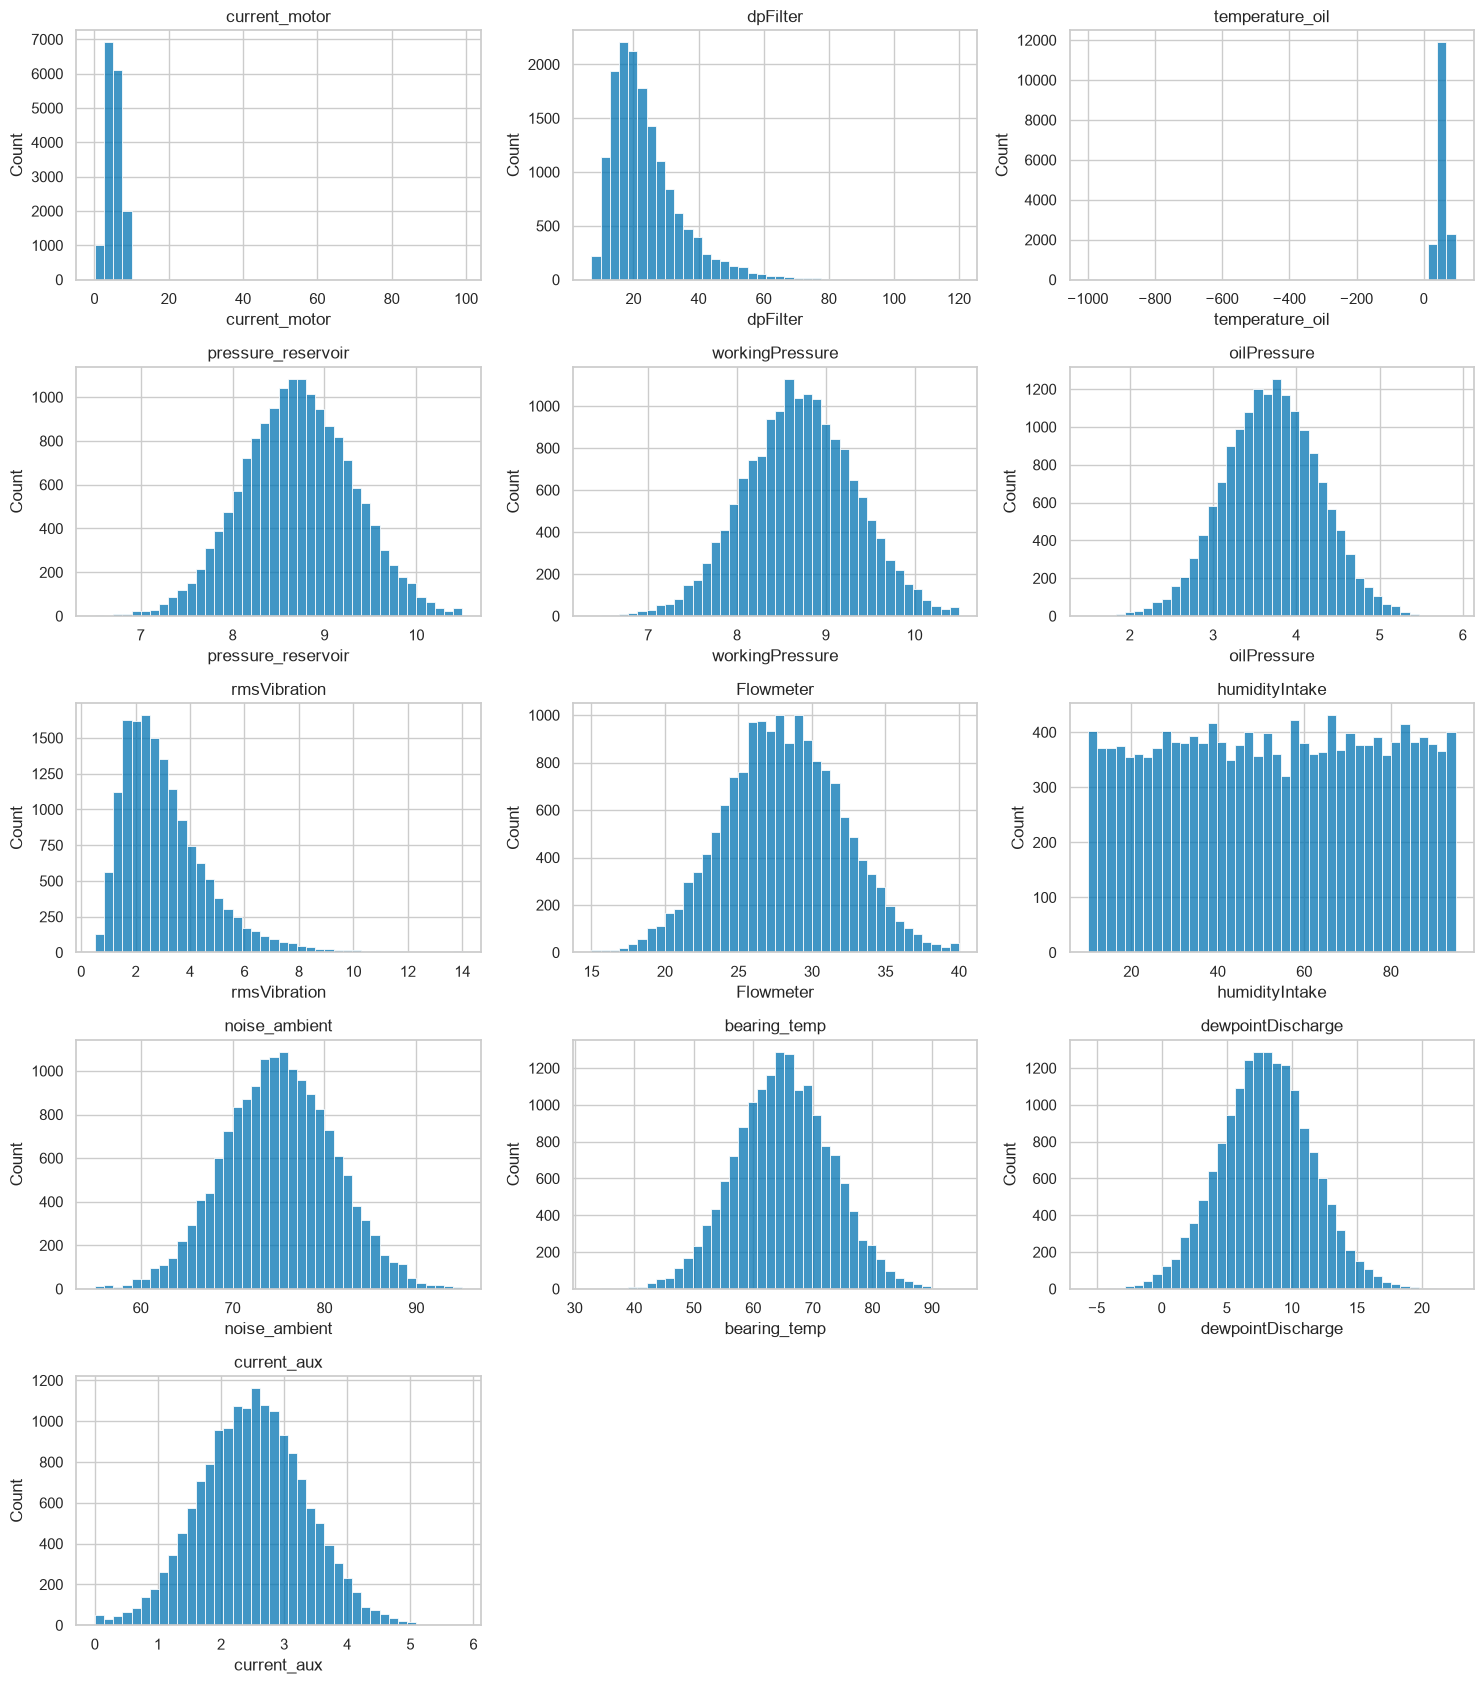

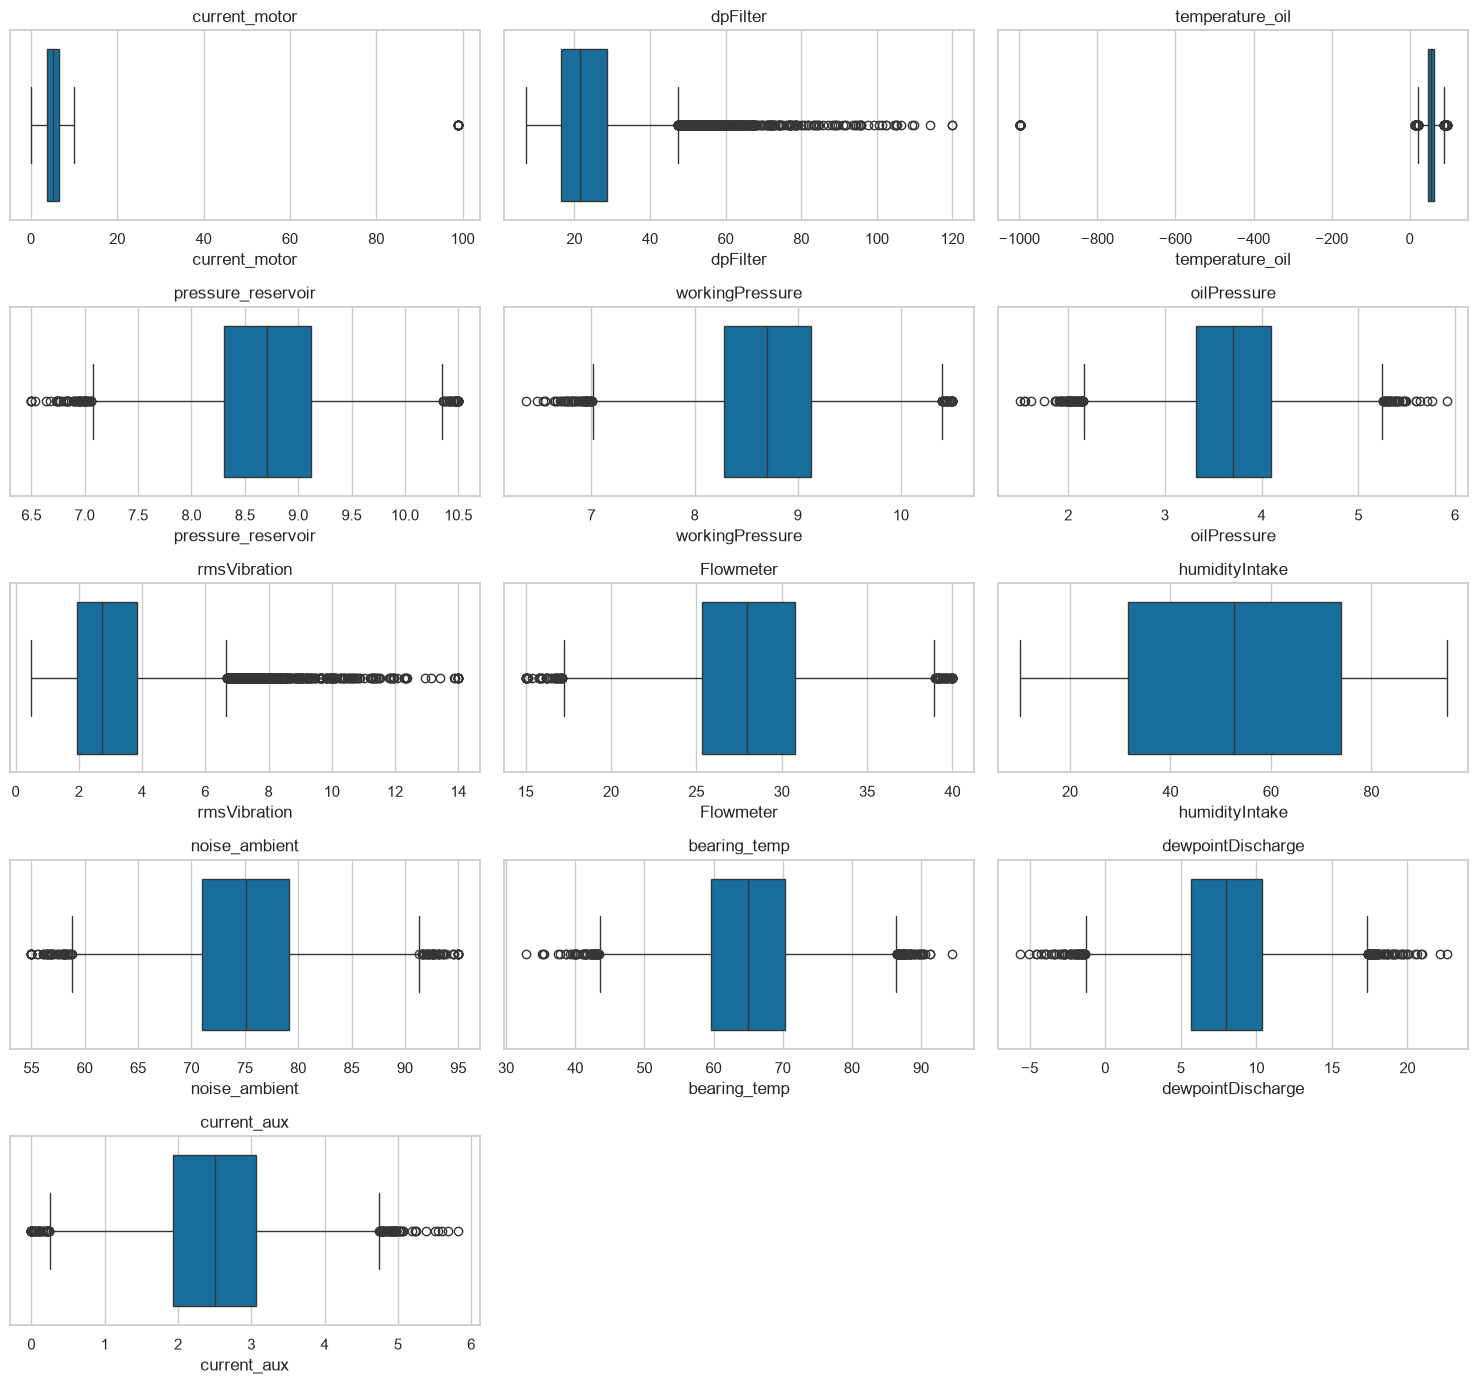

,count,proportion
Failure,,
0,14148,0.8822
1,1890,0.1178


In [3]:
eda = raw["readings"].copy()
descriptions = {
"current_motor":"motor current", "dpFilter":"filter pressure difference", "temperature_oil":"oil temperature",
"pressure_reservoir":"reservoir pressure", "workingPressure":"working pressure", "oilPressure":"oil pressure",
"rmsVibration":"RMS vibration", "Flowmeter":"flow", "humidityIntake":"intake humidity",
"noise_ambient":"ambient noise", "bearing_temp":"bearing temperature", "dewpointDischarge":"discharge dew point", "current_aux":"auxiliary current"}
desc = eda[sensors].describe(percentiles=[.05,.25,.5,.75,.95]).T
desc.insert(0,"meaning", pd.Series(descriptions))
desc["missing %"] = eda[sensors].isna().mean()*100
desc["skewness"] = eda[sensors].skew()
display(desc)
fig, axes = plt.subplots(5,3,figsize=(15,17))
for c, ax in zip(sensors, axes.flat):
    sns.histplot(eda[c].dropna(), bins=40, ax=ax)
    ax.set_title(c); ax.set_ylabel("Count")
for ax in axes.flat[len(sensors):]: ax.axis("off")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(5,3,figsize=(15,14))
for c, ax in zip(sensors, axes.flat):
    sns.boxplot(x=eda[c], ax=ax); ax.set_title(c)
for ax in axes.flat[len(sensors):]: ax.axis("off")
plt.tight_layout(); plt.show()
display(eda.groupby("Failure").size().rename("count").to_frame().assign(proportion=lambda d:d["count"]/len(eda)))


**Preliminary interpretation:** the oil-temperature histogram reveals −999, which distorts the mean and plot scale; we keep it visible at this stage. Motor current contains an extreme value of 99. Filter pressure difference and vibration have long right tails, so medians and quartiles should accompany means.

Reservoir, working and oil pressures have concentrated distributions. Flowmeter is approximately symmetric around 28. Intake humidity is roughly uniform across its observed range. Ambient noise, bearing temperature, discharge dew point and auxiliary current are approximately bell-shaped. A negative dew point is not automatically an error. These are visual descriptions, not proof of normality.

Failures account for approximately 11.78% of the raw readings. We will check the proportion after deduplication in section 1.2. High sensor values are not removed at this stage because they may represent failure signals.

## 1.1 C – Relationships between pairs of attributes
Pearson correlation describes linear association; Spearman correlation describes monotonic association and is less sensitive to extreme magnitudes. We calculate correlations using available pairs and exclude IDs. Correlation proves neither causality nor independence.

### Why inspect two correlations
Comparing Pearson and Spearman helps reveal sensitivity to extremes or nonlinear monotonic relationships. Both heatmaps use the same −1 to 1 scale. The strongest-pair table excludes the diagonal and mirrored duplicates.

Correlations use all available pairs; valid sample sizes can differ between pairs. We do not treat these exploratory correlations as formal significance tests. Scatterplots use at most 3,000 randomly selected rows to reduce overplotting. Seed 12 makes the plotted sample reproducible without changing the full-data correlation calculations.

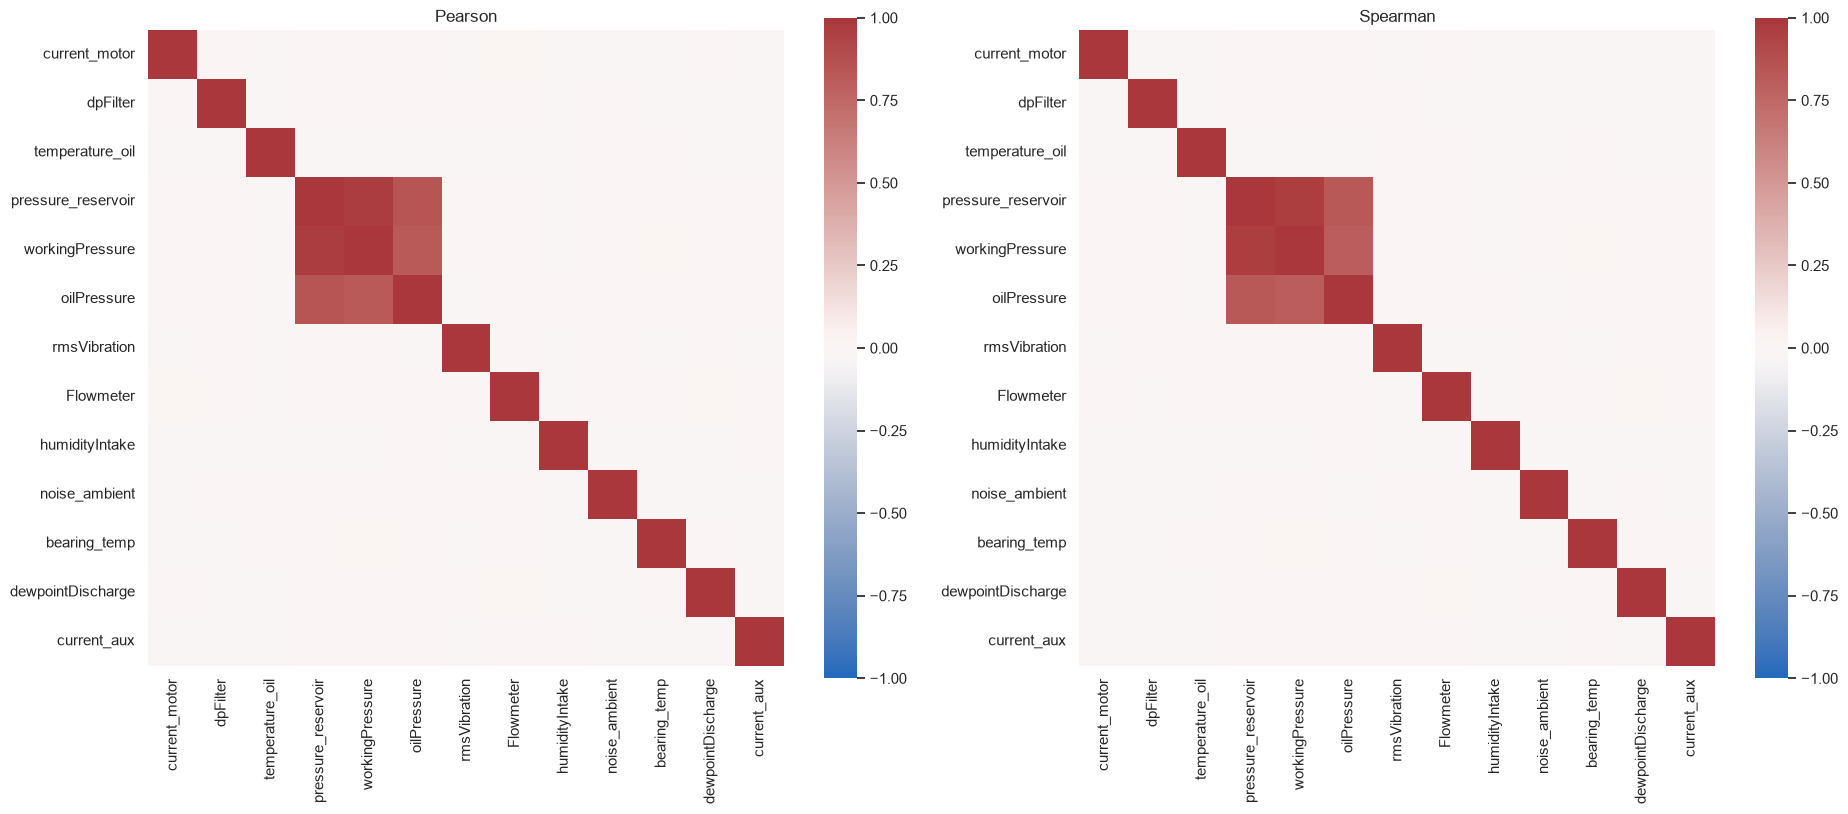

Spearman rho
pressure_reservoir workingPressure          0.9678
                   oilPressure              0.8336
workingPressure    oilPressure              0.8084
current_motor      noise_ambient           -0.0199
Flowmeter          dewpointDischarge        0.0196
rmsVibration       humidityIntake          -0.0181
workingPressure    bearing_temp             0.0158
pressure_reservoir bearing_temp             0.0147
temperature_oil    workingPressure         -0.0145
dpFilter           workingPressure          0.0143

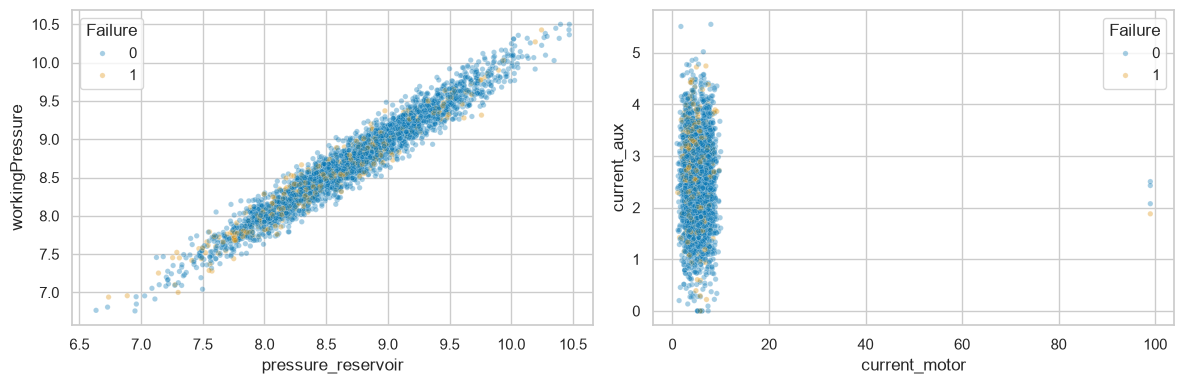

In [4]:
pearson = eda[sensors].corr(method="pearson")
spearman = eda[sensors].corr(method="spearman")
fig, axes = plt.subplots(1,2,figsize=(19,8))
for matrix, title, ax in [(pearson,"Pearson",axes[0]),(spearman,"Spearman",axes[1])]:
    sns.heatmap(matrix, vmin=-1, vmax=1, cmap="vlag", ax=ax, square=True)
    ax.set_title(title)
plt.tight_layout(); plt.show()
pairs = spearman.where(np.triu(np.ones(spearman.shape),1).astype(bool)).stack().rename("Spearman rho").to_frame()
pairs["abs"] = pairs["Spearman rho"].abs()
display(pairs.sort_values("abs", ascending=False).drop(columns="abs").head(10))
fig,axes=plt.subplots(1,2,figsize=(12,4))
sample=eda.sample(min(3000,len(eda)),random_state=12)
sns.scatterplot(data=sample,x="pressure_reservoir",y="workingPressure",hue="Failure",alpha=.35,s=15,ax=axes[0])
sns.scatterplot(data=sample,x="current_motor",y="current_aux",hue="Failure",alpha=.35,s=15,ax=axes[1])
plt.tight_layout(); plt.show()


In [5]:
strongest = pairs.sort_values("abs", ascending=False).head(3)
for (a,b),row in strongest.iterrows():
    display(Markdown(f"**Preliminary relationship between {a} and {b}:** Spearman rho = {row['Spearman rho']:.3f}. These are original readings; cleaning may affect the result."))

**Preliminary relationship between pressure_reservoir and workingPressure:** Spearman rho = 0.968. These are original readings; cleaning may affect the result.

**Preliminary relationship between pressure_reservoir and oilPressure:** Spearman rho = 0.834. These are original readings; cleaning may affect the result.

**Preliminary relationship between workingPressure and oilPressure:** Spearman rho = 0.808. These are original readings; cleaning may affect the result.

## 1.1 D – Relationships with Failure
Here we use only sensors and the target from readings. Device and gateway metadata are attached in section 1.2, keeping the initial exploration separate from integration.

### Why compare groups defined by the target
A sensor's overall distribution does not show whether it is associated with failure. We compare Failure = 0 and Failure = 1. Means can reflect tail effects, medians describe typical values, and boxplots show overlap. Extreme points are hidden only in these grouped plots for readability; observations are not removed.

Failure                            0         1
current_motor      count  14148.0000 1890.0000
                   mean       5.3139    4.9070
                   median     5.1677    4.5267
dpFilter           count  13874.0000 1555.0000
                   mean      23.5762   27.9655
                   median    20.9988   24.4853
temperature_oil    count  14148.0000 1890.0000
                   mean      51.1161   51.0451
                   median    54.7621   55.2478
pressure_reservoir count  14148.0000 1890.0000
                   mean       8.7296    8.5513
                   median     8.7244    8.5526
workingPressure    count  14148.0000 1890.0000
                   mean       8.7280    8.5474
                   median     8.7267    8.5488
oilPressure        count  14148.0000 1890.0000
                   mean       3.7227    3.5814
                   median     3.7239    3.5840
rmsVibration       count  13835.0000 1526.0000
                   mean       3.0687    3.2711
                   median     2.7169    2.9025
Flowmeter          count  14148.0000 1890.0000
                   mean      28.0424   27.8367
                   median    27.9781   27.9106
humidityIntake     count  13405.0000 1806.0000
                   mean      52.7038   52.7958
                   median    52.6902   51.7879
noise_ambient      count  14148.0000 1890.0000
                   mean      75.0754   75.1645
                   median    75.0801   75.0255
bearing_temp       count  14148.0000 1890.0000
                   mean      64.7743   66.8789
                   median    64.7669   66.8857
dewpointDischarge  count  14148.0000 1890.0000
                   mean       7.9189    8.7071
                   median     7.9225    8.7485
current_aux        count  14148.0000 1890.0000
                   mean       2.4837    2.6396
                   median     2.4828    2.6376

,Pearson with Failure
pressure_reservoir,-0.0956
workingPressure,-0.0938
oilPressure,-0.0801
current_motor,-0.0378
Flowmeter,-0.0166
temperature_oil,-0.0004
humidityIntake,0.0012
noise_ambient,0.0048
rmsVibration,0.0372
current_aux,0.0604


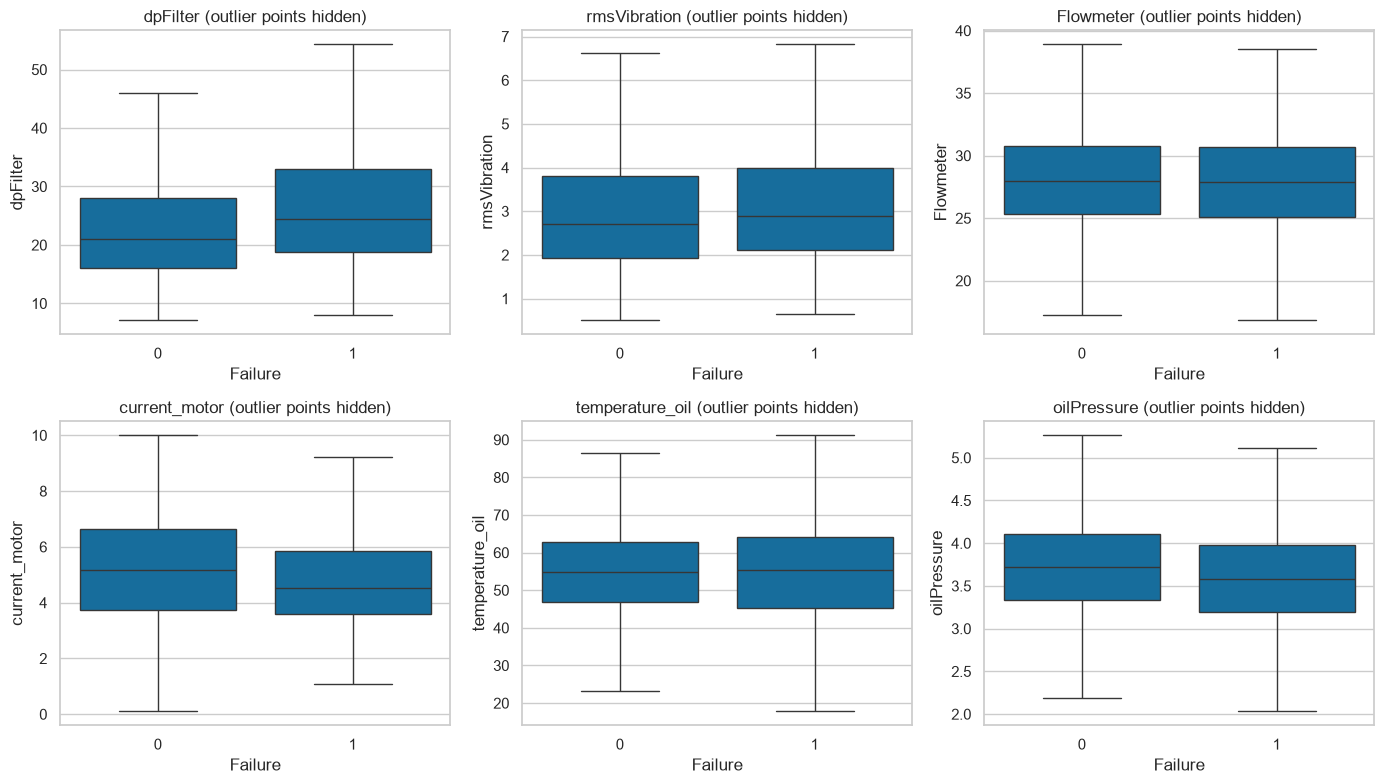

In [6]:
display(eda.groupby("Failure")[sensors].agg(["count","mean","median"]).T)
target_corr = eda[sensors].corrwith(eda.Failure).sort_values()
display(target_corr.rename("Pearson with Failure").to_frame())
fig,axes=plt.subplots(2,3,figsize=(14,8))
for c,ax in zip(["dpFilter","rmsVibration","Flowmeter","current_motor","temperature_oil","oilPressure"],axes.flat):
    sns.boxplot(data=eda,x="Failure",y=c,showfliers=False,ax=ax)
    ax.set_title(c+" (outlier points hidden)")
plt.tight_layout(); plt.show()


**Preliminary conclusion:** the group distributions overlap, so one sensor is unlikely to perfectly separate the classes. The dpFilter shift and smaller vibration difference motivate further investigation. Duplicates and sentinels may still affect means and correlations, so inferential testing follows initial cleaning.

## 1.1 E – Initial interpretation and next steps
Pressure sensors are related and may carry redundant information. Weak marginal correlations do not exclude nonlinear or combined predictive value. dpFilter and RMS vibration are candidates for further investigation of their association with Failure.

To investigate model, duty class or firmware, the tables need to be joined on unitId after harmonising key formats and checking uniqueness. Exact duplicates can overweight measurements, while −999 distorts temperature statistics. Clear errors will be treated separately from uncertain extreme values, for which two alternatives will be compared.

Repeated readings from one device are not necessarily independent. This must be considered in hypothesis tests and future train/test splitting. Chronology and the availability of metadata at prediction time also require attention.

## 1.2 A – Integration and initial cleaning
The following processing retains the teammate's original methods and order. Input loading is shared with section 1.1. The repeated initial head/info inspection is omitted because section 1.1 A already covers the source structure. Technical changes are limited to shared variables, English labels, plotting display and saving an unfilled copy for Hypothesis 2.

### Harmonising unitId

The three tables describe the same machines, but `unitId` is stored in different formats. In `readings` it is a string such as `U01329`, while in the other tables it is a plain number. Before merging, every table gets the same numeric key (`int64`).

The cell below extracts the digits, converts them to numbers and casts the result to `int64`. Values without any digits are dropped by `dropna()`.

In [7]:
units_num = pd.to_numeric(
    units['unitId'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce'
).dropna().astype('int64')

readings_num = pd.to_numeric(
    readings['unitId'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce'
).dropna().astype('int64')

gateways_num = pd.to_numeric(
    gateways['unitId'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce'
).dropna().astype('int64')

for name, s in [('units', units_num), ('readings', readings_num), ('gateways', gateways_num)]:
    print(f"{name}: count={len(s)}, unique={s.nunique()}, min={s.min()}, max={s.max()}")

print("units ∩ readings:", len(set(units_num) & set(readings_num)))
print("gateways ∩ readings:", len(set(gateways_num) & set(readings_num)))
print("units ∩ gateways:", len(set(units_num) & set(gateways_num)))

units['unitId'] = units_num
readings['unitId'] = readings_num
gateways['unitId'] = gateways_num

units: count=2000, unique=2000, min=1, max=2000
readings: count=16038, unique=2125, min=1, max=90499
gateways: count=2000, unique=2000, min=1, max=2000
units ∩ readings: 2000
gateways ∩ readings: 2000
units ∩ gateways: 2000


After the conversion, every `unitId` in `units` and `gateways` is also in the other two tables. `readings` has 125 additional IDs that do not exist in `units`. These are kept for now and are handled by the merge and the missing-value step.

**Dates:** the date columns use several formats in the same column. They are parsed with `format='mixed'` and `dayfirst=True`. Ambiguous slash dates (for example `02/03/2023`) should be checked, because `dayfirst` decides how they are read.

In [8]:
readings['cycleTs'] = pd.to_datetime(readings.cycleTs, format='mixed', dayfirst=True)
units['overhaul_last'] = pd.to_datetime(units.overhaul_last, format='mixed', dayfirst=True)

In [9]:
readings.head()

,unitId,cycleTs,current_motor,dpFilter,temperature_oil,pressure_reservoir,workingPressure,oilPressure,rmsVibration,Flowmeter,humidityIntake,noise_ambient,bearing_temp,dewpointDischarge,current_aux,Failure
0,1329,2023-05-25 00:00:00,6.7193,21.8777,64.7775,8.1145,7.9155,3.0207,4.6135,30.1008,65.3655,70.2995,57.6978,8.8816,3.0681,0
1,1258,2023-09-06 00:00:00,3.1381,19.5266,34.5795,8.8247,8.6824,3.2942,1.8372,37.3440,37.7168,77.5020,65.5504,9.5817,1.2577,0
2,1227,2023-03-11 00:00:00,5.8223,30.6854,61.1067,9.4746,9.4281,4.2659,2.3710,26.4613,40.1800,88.5194,71.5323,9.9230,2.1789,0
3,1286,2023-03-16 00:00:00,6.0249,17.4209,39.9944,8.6176,8.5375,3.5358,1.7943,29.3423,67.9159,76.3032,69.8379,3.6270,3.2719,0
4,1142,2023-02-23 22:22:00,4.0273,18.4386,64.3345,8.6367,8.7439,3.5991,3.0907,27.1922,39.5943,71.0887,59.3005,7.9404,2.6990,0


In [10]:
units.head()

,year_commission,overhaul_last,codeModel,unitId,regionInstall,owner_operator,serial_number,depotId,duty_class,line_code,hours_service,code_fleet,Manufacturer
0,2022,2018-05-21,XC-7,1,Schrobenhausen,Jones-Davies,YK-9092-54795,106,3,L1,9388.9000,FD,Kabus Rogner GmbH
1,2020,2020-10-07,APU-15,2,Ahaus,Carvalho Leite S/A,MK-5868-13759,13,L,L6,14764.5000,FE,Köhler OHG mbH
2,2022,2017-05-07,APU-15,3,São Salvador de Lordelo,Murray Group,PI-0711-68546,62,light,L1,8476.6000,FB,Jähn AG
3,2022,2021-11-16,APU-15,4,Amora,Austermühle,JJ-6819-11879,3,3,L3,8316.2000,FB,Sá Leite Lda.
4,2022,2024-08-13,APU-20,5,Douglasside,Murray Group,HJ-1947-75387,115,2,L3,8810.8000,FB,Hamilton-Smith


### Checking exact duplicates

The dates are now parsed. Next, I check whether any table contains fully duplicated rows.

Only `readings` has duplicates (237 rows). `gateways` and `units` have none.

In [11]:
gate_dup = gateways.duplicated()
read_dup = readings.duplicated()
unit_dup = units.duplicated()
gate_dup[gate_dup == True]

Series([], dtype: bool)

In [12]:
read_dup[read_dup == True]

15801    True
15802    True
15803    True
15804    True
15805    True
         ... 
16033    True
16034    True
16035    True
16036    True
16037    True
Length: 237, dtype: bool

In [13]:
unit_dup[unit_dup == True]

Series([], dtype: bool)

Duplicates are removed from `readings` only. `drop_duplicates()` keeps the first occurrence of each identical row.

In [14]:
readings = readings.drop_duplicates()
readings

,unitId,cycleTs,current_motor,dpFilter,temperature_oil,pressure_reservoir,workingPressure,oilPressure,rmsVibration,Flowmeter,humidityIntake,noise_ambient,bearing_temp,dewpointDischarge,current_aux,Failure
0,1329,2023-05-25 00:00:00,6.7193,21.8777,64.7775,8.1145,7.9155,3.0207,4.6135,30.1008,65.3655,70.2995,57.6978,8.8816,3.0681,0
1,1258,2023-09-06 00:00:00,3.1381,19.5266,34.5795,8.8247,8.6824,3.2942,1.8372,37.3440,37.7168,77.5020,65.5504,9.5817,1.2577,0
2,1227,2023-03-11 00:00:00,5.8223,30.6854,61.1067,9.4746,9.4281,4.2659,2.3710,26.4613,40.1800,88.5194,71.5323,9.9230,2.1789,0
3,1286,2023-03-16 00:00:00,6.0249,17.4209,39.9944,8.6176,8.5375,3.5358,1.7943,29.3423,67.9159,76.3032,69.8379,3.6270,3.2719,0
4,1142,2023-02-23 22:22:00,4.0273,18.4386,64.3345,8.6367,8.7439,3.5991,3.0907,27.1922,39.5943,71.0887,59.3005,7.9404,2.6990,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15796,4,2023-09-01 00:00:00,7.2244,34.3217,74.9732,9.2655,9.4413,4.7311,3.2188,30.5600,59.6727,72.6753,59.1765,9.9858,3.1635,0
15797,942,2023-12-18 00:00:00,7.6782,11.9185,67.4168,8.3988,8.3123,3.5032,2.6174,25.5180,19.5903,77.1505,72.6889,10.8536,2.4914,0
15798,981,2023-04-01 14:40:00,4.2219,18.4179,64.8154,8.7032,8.6077,3.4548,3.8406,27.7839,34.5677,85.1885,45.1839,12.6866,3.2916,0
15799,1383,2023-04-28 00:00:00,4.3474,14.1508,36.7328,8.9186,8.9551,3.9453,2.3659,27.5272,76.2358,75.0634,75.1277,5.5540,3.3719,1


### Joining the tables

The tables are combined on `unitId`:

1. `units` and `gateways` are joined with an inner join, so only machines present in both are kept.
2. The readings are attached with a right join, so every reading is kept.

Readings whose `unitId` has no matching machine get missing values in the unit columns. These rows are removed in the missing-value step.

In [15]:
data = units.merge(gateways,on='unitId', how='inner')
data = data.merge(readings, on='unitId', how='right')
data

,year_commission,overhaul_last,codeModel,unitId,regionInstall,owner_operator,serial_number,depotId_x,duty_class,line_code,...,workingPressure,oilPressure,rmsVibration,Flowmeter,humidityIntake,noise_ambient,bearing_temp,dewpointDischarge,current_aux,Failure
0,2023.0000,2019-04-05,APU-20,1329,Lübeck,Duncan-Lynch,LJ-7674-12279,99.0000,H,L4,...,7.9155,3.0207,4.6135,30.1008,65.3655,70.2995,57.6978,8.8816,3.0681,0
1,2017.0000,2019-07-05,APU-15,1258,South Lesliemouth,Sá Leite Lda.,JX-7532-71445,32.0000,1,L4,...,8.6824,3.2942,1.8372,37.3440,37.7168,77.5020,65.5504,9.5817,1.2577,0
2,2021.0000,2017-02-22,XC-7,1227,Walterton,Mülichen AG,VZ-4260-35538,58.0000,N,L5,...,9.4281,4.2659,2.3710,26.4613,40.1800,88.5194,71.5323,9.9230,2.1789,0
3,2023.0000,2022-11-13,XC-7,1286,São Salvador de Lordelo,Stumpf GmbH,JB-4632-99222,17.0000,3,L3,...,8.5375,3.5358,1.7943,29.3423,67.9159,76.3032,69.8379,3.6270,3.2719,0
4,2023.0000,2021-06-23,APU-20,1142,Setúbal,Jones-Davies,EI-0981-89563,54.0000,med,L4,...,8.7439,3.5991,3.0907,27.1922,39.5943,71.0887,59.3005,7.9404,2.6990,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15796,2022.0000,2021-11-16,APU-15,4,Amora,Austermühle,JJ-6819-11879,3.0000,3,L3,...,9.4413,4.7311,3.2188,30.5600,59.6727,72.6753,59.1765,9.9858,3.1635,0
15797,2023.0000,2021-08-10,XC-7,942,East Crystal,Austin and Sons,QM-2002-68469,85.0000,heavy,L1,...,8.3123,3.5032,2.6174,25.5180,19.5903,77.1505,72.6889,10.8536,2.4914,0
15798,2021.0000,2022-12-06,APU-15,981,North Jacobton,Ortmann GmbH & Co. KGaA,GQ-5834-48181,24.0000,1,L6,...,8.6077,3.4548,3.8406,27.7839,34.5677,85.1885,45.1839,12.6866,3.2916,0
15799,2020.0000,2019-06-07,APU-12,1383,Lübeck,Rogge Wiek AG,UV-6045-40373,90.0000,2,L5,...,8.9551,3.9453,2.3659,27.5272,76.2358,75.0634,75.1277,5.5540,3.3719,1


In [16]:
data_dup = data.duplicated()
data_dup[data_dup == True]

Series([], dtype: bool)

After the merge, the table has no duplicate rows. Next, I check the share of missing values in each column.

In [17]:
round((data.isnull().sum() / data.shape[0]) * 100, 2)

year_commission      0.9100
overhaul_last        0.9100
codeModel            0.9100
unitId               0.0000
regionInstall        0.9100
owner_operator       0.9100
serial_number        0.9100
depotId_x            0.9100
duty_class           0.9100
line_code            0.9100
hours_service        5.7900
code_fleet           0.9100
Manufacturer         0.9100
Vendor               0.9100
firmwareVersion      0.9100
lon                  0.9100
macAddress           0.9100
dbm_signal           0.9100
lat                  0.9100
gatewayId            0.9100
depotId_y            0.9100
ipv4                 0.9100
Technician           0.9100
cycleTs              0.0000
current_motor        0.0000
dpFilter             3.7700
temperature_oil      0.0000
pressure_reservoir   0.0000
workingPressure      0.0000
oilPressure          0.0000
rmsVibration         4.2100
Flowmeter            0.0000
humidityIntake       5.1400
noise_ambient        0.0000
bearing_temp         0.0000
dewpointDischarge   

### Missing metadata

About 0.91% of the values are missing in 21 columns. Next I check whether these missing values come from the same rows.

In [18]:
no_id = data['codeModel'].isna()

cols_091 = ['year_commission', 'overhaul_last', 'codeModel', 'regionInstall',
            'owner_operator', 'serial_number', 'depotId_x', 'duty_class',
            'line_code', 'code_fleet', 'Manufacturer', 'Vendor', 'firmwareVersion',
            'lon', 'macAddress', 'dbm_signal', 'lat', 'gatewayId', 'depotId_y',
            'ipv4', 'Technician']

print("without id:", no_id.sum())
print("rows with Nan in this columns:", data[cols_091].isna().any(axis=1).sum())
print("The same one", (no_id == data[cols_091].isna().any(axis=1)).all())

without id: 144
rows with Nan in this columns: 144
The same one True


All the 0.91% missing values come from the same 144 rows. These are readings whose `unitId` has no matching record in `units` or `gateways` (orphan records). Their machine information cannot be filled in, so they are dropped.

In [19]:
data = data.dropna(subset=['codeModel']).reset_index(drop=True)

In [20]:
# Snapshot for Hypothesis 2: observed readings before filling or capping.
hypothesis2_observed = data.copy(deep=True)

In [21]:
round((data.isnull().sum() / data.shape[0]) * 100, 2)

year_commission      0.0000
overhaul_last        0.0000
codeModel            0.0000
unitId               0.0000
regionInstall        0.0000
owner_operator       0.0000
serial_number        0.0000
depotId_x            0.0000
duty_class           0.0000
line_code            0.0000
hours_service        4.9200
code_fleet           0.0000
Manufacturer         0.0000
Vendor               0.0000
firmwareVersion      0.0000
lon                  0.0000
macAddress           0.0000
dbm_signal           0.0000
lat                  0.0000
gatewayId            0.0000
depotId_y            0.0000
ipv4                 0.0000
Technician           0.0000
cycleTs              0.0000
current_motor        0.0000
dpFilter             3.7600
temperature_oil      0.0000
pressure_reservoir   0.0000
workingPressure      0.0000
oilPressure          0.0000
rmsVibration         4.1900
Flowmeter            0.0000
humidityIntake       5.1200
noise_ambient        0.0000
bearing_temp         0.0000
dewpointDischarge   

After dropping these rows, the remaining missing values are in `hours_service` (about 4.9%), `dpFilter`, `rmsVibration` and `humidityIntake` (about 4% each).

### Missing service hours

Before filling `hours_service`, I check whether a missing value is related to failures. The indicator `service_missing` marks missing values with 1.

In [22]:
data['service_missing'] = data['hours_service'].isna().astype(int)
print(data.groupby('service_missing')['Failure'].agg(['mean', 'size']))

                  mean   size
service_missing              
0               0.1173  14886
1               0.1245    771


The failure rate is about 12.5% when `hours_service` is missing and about 11.7% when it is present, so the difference is small.

Missing values are filled with 0, which means "no recorded service hours". This is an assumption, not a verified fact. The `service_missing` indicator is created before filling, so the information is not lost. It remains in the data for the sensitivity check.

In [23]:
data['hours_service'] = data['hours_service'].fillna(0)

### Missing sensor readings

`dpFilter`, `rmsVibration` and `humidityIntake` are time series for each machine. Missing values are filled by linear interpolation within each machine, ordered by `cycleTs`. `limit_direction='both'` also fills gaps at the start or end of a machine's series.

This is done on the whole dataset. In Phase 2 the same step should be fitted on the training data only, to avoid leakage into the test set.

In [24]:
sensor_cols = ['dpFilter', 'rmsVibration', 'humidityIntake']

data = data.sort_values(['unitId', 'cycleTs'])
data[sensor_cols] = (
    data.groupby('unitId')[sensor_cols]
        .transform(lambda s: s.interpolate(limit_direction='both'))
)

**Method limitation:** sorting before default linear interpolation interpolates by row position, not elapsed time. Filling in both directions can use future observations. A train/test split alone does not make this causal; future prediction would require a past-only filling rule. This implementation is kept as supplied.

In [25]:
round((data.isnull().sum() / data.shape[0]) * 100, 2)

year_commission      0.0000
overhaul_last        0.0000
codeModel            0.0000
unitId               0.0000
regionInstall        0.0000
owner_operator       0.0000
serial_number        0.0000
depotId_x            0.0000
duty_class           0.0000
line_code            0.0000
hours_service        0.0000
code_fleet           0.0000
Manufacturer         0.0000
Vendor               0.0000
firmwareVersion      0.0000
lon                  0.0000
macAddress           0.0000
dbm_signal           0.0000
lat                  0.0000
gatewayId            0.0000
depotId_y            0.0000
ipv4                 0.0000
Technician           0.0000
cycleTs              0.0000
current_motor        0.0000
dpFilter             0.0000
temperature_oil      0.0000
pressure_reservoir   0.0000
workingPressure      0.0000
oilPressure          0.0000
rmsVibration         0.0000
Flowmeter            0.0000
humidityIntake       0.0000
noise_ambient        0.0000
bearing_temp         0.0000
dewpointDischarge   

## 1.2 B – Integrity and abnormal values

Both `units` and `gateways` contain `depotId`, so the merge creates `depotId_x` and `depotId_y`. The check below finds no rows where they differ. One copy is dropped, `depotId_x` is renamed to `depotId`. The `service_missing` indicator is retained.

In [26]:
depo = data['depotId_x'] == data['depotId_y']
depo[depo == False]

Series([], dtype: bool)

In [27]:
data = data.drop('depotId_y', axis=1)
data.rename(columns={'depotId_x': 'depotId'}, inplace=True)

### Numeric range checks

For each numeric column I look at the minimum, maximum, mean, standard deviation, and the number of negative and zero values. The goal is to find impossible or suspicious values.

In [28]:
num_cols = data.select_dtypes(include='number').columns.drop(['Failure', 'unitId'], errors='ignore')
desc = data[num_cols].describe().T
desc['neg_count'] = (data[num_cols] < 0).sum()
desc['zero_count'] = (data[num_cols] == 0).sum()
print(desc[['min', 'max', 'mean', 'std', 'neg_count', 'zero_count']].round(2))

                         min        max       mean       std  neg_count  \
year_commission    2012.0000  2024.0000  2020.4700    2.5000          0   
depotId               0.0000   119.0000    55.2500   34.4000          0   
hours_service         0.0000 45000.0000 13514.9700 9141.4500          0   
lon                  -9.3000    -6.2000    -7.7800    0.8900      15657   
dbm_signal         -105.6000   -40.0000   -70.1200   10.2400      15657   
lat                  38.6000    41.7000    40.1500    0.8900          0   
current_motor         0.1000    99.0000     5.2700    3.5000          0   
dpFilter              7.0800   120.0000    24.0300   11.2700          0   
temperature_oil    -999.0000    95.0000    51.4300   61.2400         51   
pressure_reservoir    6.5000    10.5000     8.7100    0.6000          0   
workingPressure       6.3600    10.5000     8.7100    0.6200          0   
oilPressure           1.5000     5.9100     3.7100    0.5700          0   
rmsVibration          0.5

The minimum of `temperature_oil` is -999. This is a sentinel code, not a real temperature. The code replaces it with NaN. The NaN values are then interpolated together with `current_aux` (see below).

Zeros in `depotId` and `current_aux` are checked in the next cells.

In [29]:
data['temperature_oil'] = data['temperature_oil'].replace(-999, np.nan)

In [30]:
data.isnull().sum()

year_commission        0
overhaul_last          0
codeModel              0
unitId                 0
regionInstall          0
owner_operator         0
serial_number          0
depotId                0
duty_class             0
line_code              0
hours_service          0
code_fleet             0
Manufacturer           0
Vendor                 0
firmwareVersion        0
lon                    0
macAddress             0
dbm_signal             0
lat                    0
gatewayId              0
ipv4                   0
Technician             0
cycleTs                0
current_motor          0
dpFilter               0
temperature_oil       51
pressure_reservoir     0
workingPressure        0
oilPressure            0
rmsVibration           0
Flowmeter              0
humidityIntake         0
noise_ambient          0
bearing_temp           0
dewpointDischarge      0
current_aux            0
Failure                0
service_missing        0
dtype: int64

In [31]:
data.loc[data['depotId']==0, 'unitId'].nunique()

19

In [32]:
per_unit = data.groupby('unitId')['depotId'].nunique()
print("Machines with multiple depotId values:", (per_unit > 1).sum())
print("depotId values in machines assigned zero:",
      data.loc[data['depotId']==0].groupby('unitId')['depotId'].first().value_counts().head())

Machines with multiple depotId values: 0
depotId values in machines assigned zero: depotId
0.0000    19
Name: count, dtype: int64


**`depotId = 0`:** 19 machines have depot 0. Each of them has only this one value across all its rows, and no machine has more than one depot. Zero therefore looks like a valid placeholder code, not a data error, so these rows are kept.

In [33]:
zero_aux = data[data['current_aux'] == 0]
print(zero_aux.groupby('unitId').size().describe())

count   27.0000
mean     1.0000
std      0.0000
min      1.0000
25%      1.0000
50%      1.0000
75%      1.0000
max      1.0000
dtype: float64


In [34]:
zero_idx = data.index[data['current_aux'] == 0]
for i in zero_idx[:3]:
    u = data.loc[i, 'unitId']
    print(data.loc[data['unitId'] == u, ['cycleTs', 'current_aux']].assign(
        is_zero=lambda d: d['current_aux'] == 0).to_string(), '\n')

                  cycleTs  current_aux  is_zero
9061  2023-01-12 03:53:00       2.3155    False
12613 2023-02-16 19:05:00       3.4045    False
5990  2023-03-18 00:00:00       3.6532    False
11997 2023-03-21 00:00:00       2.4774    False
3072  2023-03-22 08:48:00       1.2534    False
14488 2023-04-24 00:00:00       3.2251    False
13034 2023-07-19 00:00:00       3.1519    False
13869 2023-07-19 00:00:00       2.0121    False
5272  2023-10-28 00:12:00       2.7995    False
4888  2023-11-24 00:00:00       4.1440    False
14826 2023-12-20 00:00:00       0.0000     True
10444 2023-12-22 00:00:00       2.8806    False
13365 2023-12-27 00:00:00       2.4828    False 

                  cycleTs  current_aux  is_zero
2917  2023-01-18 00:00:00       2.6425    False
7269  2023-02-09 00:00:00       2.0700    False
10088 2023-03-27 00:00:00       2.0301    False
14616 2023-07-02 00:00:00       2.4676    False
7600  2023-07-15 00:00:00       2.2806    False
13010 2023-08-04 00:00:00       0.0000

In [35]:
data['current_aux'] = data['current_aux'].replace(0.0, np.nan)

**`current_aux = 0`:** there are 27 zero values, and each affected machine has exactly one zero. The zeros look like single-reading sensor dropouts, because the values before and after are close to normal. The zeros are set to NaN and interpolated, in the same way as `temperature_oil`.

**Assumption to verify:** an isolated zero is not sufficient proof of sensor dropout; it could represent a stopped component. The original replacement is retained, but its physical validity needs confirmation. Likewise, a stable depot code of zero does not establish what that code means.

In [36]:
abnormal_cols = ['current_aux', 'temperature_oil']

data = data.sort_values(['unitId', 'cycleTs'])
data[abnormal_cols] = (
    data.groupby('unitId')[abnormal_cols]
        .transform(lambda s: s.interpolate(limit_direction='both'))
)

## 1.2 C – Two techniques for outlier treatment
Numeric sensor columns are checked using the IQR rule. Both row removal and percentile capping are run on separate copies. We count affected failure readings because extreme observations may carry the signal we want to predict.

In [37]:
exclude = ['unitId', 'depotId', 'Failure', 'service_missing', 'year_commission',
           'lon', 'lat', 'dbm_signal', 'hours_service']
num_cols = [c for c in data.select_dtypes(include='number').columns if c not in exclude]
print(num_cols)

['current_motor', 'dpFilter', 'temperature_oil', 'pressure_reservoir', 'workingPressure', 'oilPressure', 'rmsVibration', 'Flowmeter', 'humidityIntake', 'noise_ambient', 'bearing_temp', 'dewpointDischarge', 'current_aux']


In [38]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

iqr_mask = pd.Series(False, index=data.index)
iqr_counts = {}
for col in num_cols:
    lo, hi = iqr_bounds(data[col])
    out = (data[col] < lo) | (data[col] > hi)
    iqr_counts[col] = out.sum()
    iqr_mask |= out

print(pd.Series(iqr_counts, name="IQR outliers").to_string())
print(f"\nRows with at least one IQR outlier: {iqr_mask.sum()} of {len(data)}")
print(data.loc[iqr_mask, "Failure"].value_counts())

current_motor          16
dpFilter              700
temperature_oil       109
pressure_reservoir    102
workingPressure       101
oilPressure           103
rmsVibration          568
Flowmeter              97
humidityIntake          0
noise_ambient          94
bearing_temp          122
dewpointDischarge     120
current_aux            99

Rows with at least one IQR outlier: 2007 of 15657
Failure
0    1661
1     346
Name: count, dtype: int64


In [39]:
data_clip = data.copy()
for col in num_cols:
    lo, hi = data[col].quantile([0.05, 0.95])
    data_clip[col] = data[col].clip(lower=lo, upper=hi)

clipped = {c: (data[c] != data_clip[c]).sum() for c in num_cols}
print(pd.Series(clipped, name="values clipped").to_string())

current_motor         1566
dpFilter              1566
temperature_oil       1566
pressure_reservoir    1566
workingPressure       1566
oilPressure           1566
rmsVibration          1566
Flowmeter             1566
humidityIntake        1566
noise_ambient         1566
bearing_temp          1566
dewpointDischarge     1566
current_aux           1566


### Technique 1 – Removing IQR outliers

Rows flagged by the IQR rule in any numeric column are removed. This shrinks the data and also removes failure rows that happen to be extreme.

In [40]:
data_removed = data.loc[~iqr_mask].copy()

print("Rows before:", len(data), "| after IQR removal:", len(data_removed))
print("Failures before:", int(data["Failure"].sum()), "| after:", int(data_removed["Failure"].sum()))
print("Failure rate before:", round(data["Failure"].mean(), 4), "| after:", round(data_removed["Failure"].mean(), 4))

Rows before: 15657 | after IQR removal: 13650
Failures before: 1842 | after: 1496
Failure rate before: 0.1176 | after: 0.1096


### Technique 2 – Capping at the 5th and 95th percentiles

Each numeric column is limited to its own 5th and 95th percentile. Every row is kept, but extreme values are moved to the limit.

In [41]:
data_capped = data.copy()
for col in num_cols:
    lo, hi = data[col].quantile([0.05, 0.95])
    data_capped[col] = data[col].clip(lower=lo, upper=hi)

print("Rows before:", len(data), "| after capping:", len(data_capped))
print("Failures before:", int(data["Failure"].sum()), "| after capping:", int(data_capped["Failure"].sum()))

Rows before: 15657 | after capping: 15657
Failures before: 1842 | after capping: 1842


### Comparing the two techniques

To see the effect, the same check is run on all three versions of the data: the mean and spread of `Flowmeter`, and the AUC of `Flowmeter` for separating failure from non-failure rows (one-sided Mann-Whitney U test).

`Flowmeter` is used here because it is a sensor column that was treated by both techniques, and it is the example variable in the assignment.

In [42]:
def compare(df, label):
    f1 = df.loc[df["Failure"] == 1, "Flowmeter"]
    f0 = df.loc[df["Failure"] == 0, "Flowmeter"]
    u, p = mannwhitneyu(f1, f0, alternative="greater")
    print(f"{label:<14} n={len(df):>6}  failures={int(df['Failure'].sum()):>4}  "
          f"mean={df['Flowmeter'].mean():.2f}  sd={df['Flowmeter'].std():.2f}  "
          f"AUC={u / (len(f1) * len(f0)):.3f}  p={p:.2e}")

compare(data, "original")
compare(data_removed, "IQR removed")
compare(data_capped, "capped 5-95%")

original       n= 15657  failures=1842  mean=28.02  sd=4.00  AUC=0.489  p=9.29e-01
IQR removed    n= 13650  failures=1496  mean=27.99  sd=3.90  AUC=0.489  p=9.10e-01
capped 5-95%   n= 15657  failures=1842  mean=28.02  sd=3.66  AUC=0.490  p=9.28e-01


### Outlier treatment decision

**Removal is not used.** It deletes about 2,000 rows, and among them are the failure rows that the IQR rule flags. A model trained on the remaining data would see fewer failures and fewer extreme failure cases, so it would look better on paper than it would be on new machines. The comparison above shows how many failure rows are lost.

**Capping is used.** It keeps every row, including all failures, and only limits the most extreme values. Its drawback is that it changes about 10 % of the values in each column by design, because the limits are the 5th and 95th percentiles. This is a known effect of the method and is accepted here for models that are sensitive to extreme values.

## 1.3 A – Formulating and testing two hypotheses
### Hypothesis 1 – Service hours and Failure
**Teammate's hypothesis:** machines that fail have higher accumulated hours_service than machines that do not fail.

H0: the distributions of hours_service are equal for failure and non-failure rows. H1: the failure group tends to have higher values. The original significance level is α = 0.05. The original row-level test is preserved, followed by the teammate's unit-level sensitivity check.

**Interpretation limit:** repeated rows from the same machine are dependent. The row-level p-value is not a valid independent-sample measure of evidence. The later unit-level Spearman calculation asks a related but different question: whether hours are associated with the observed failure fraction. The original analysis is retained here rather than silently replaced.

We first inspect the group distributions using boxplots, Q–Q plots, Shapiro–Wilk and Levene tests.

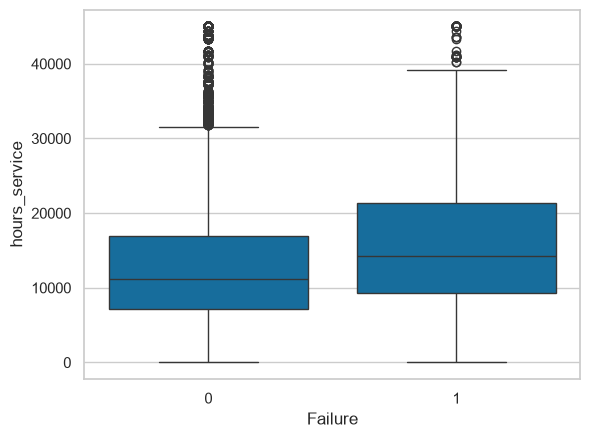

In [43]:
g0 = data.loc[data['Failure'] == 0, 'hours_service'].dropna()
g1 = data.loc[data['Failure'] == 1, 'hours_service'].dropna()

# 1. Boxplot
sns.boxplot(x='Failure', y='hours_service', data=data)
plt.show()

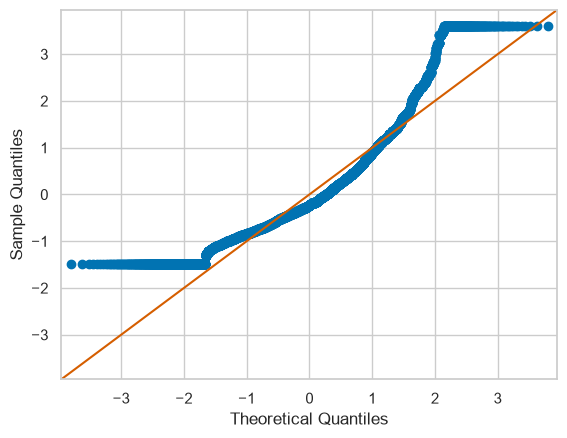

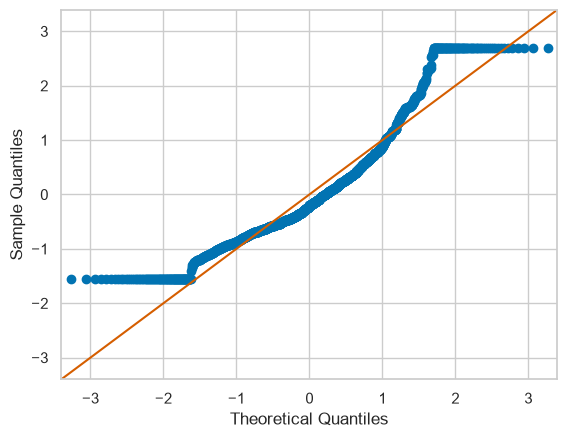

In [44]:
# 2. QQ-plot
sm.ProbPlot(g0, fit=True).qqplot(line='45')
sm.ProbPlot(g1, fit=True).qqplot(line='45')
plt.show()

In [45]:
# 3. Shapiro-Wilk (on a sample because large samples detect small deviations)
print(stats.shapiro(g0.sample(5000, random_state=0)))
print(stats.shapiro(g1.sample(min(len(g1), 5000), random_state=0)))

# 4. Levene
print(stats.levene(g0, g1))

ShapiroResult(statistic=np.float64(0.9041440400693354), pvalue=np.float64(1.6817377802741495e-48))
ShapiroResult(statistic=np.float64(0.9213772276558532), pvalue=np.float64(5.7383361454832634e-30))
LeveneResult(statistic=np.float64(97.25150886977032), pvalue=np.float64(7.118700060115289e-23))


Both groups are strongly non-normal (Shapiro-Wilk p-values far below 0.001), and their variances differ (Levene p-value far below 0.001). A t-test is therefore not appropriate, and the rank-based **Mann-Whitney U test** is used.

### Mann–Whitney U test

**Statistical qualification:** non-normality and unequal variances do not automatically rule out every t-test; Welch's test does not assume equal variances. Mann–Whitney answers a rank/distribution question and is not generally a test of means or medians. Its independence assumption still matters here.

In [46]:
u_stat, p_value = mannwhitneyu(g1, g0, alternative="greater")
n1, n0 = len(g1), len(g0)
auc = u_stat / (n1 * n0)  # probability that a random failure record has a higher value

print(f"U = {u_stat:,.0f}, p = {p_value:.2e}")
print(f"AUC = {auc:.3f}")
print("Medians:", g0.median(), "(no failure) vs", g1.median(), "(failure)")

U = 15,240,425, p = 1.07e-43
AUC = 0.599
Medians: 11140.0 (no failure) vs 14280.9 (failure)


**Result:** p ≈ 1e-43, so H0 is rejected at α = 0.05. Failure rows tend to have higher `hours_service`.

AUC is the probability that a randomly chosen failure row has a higher `hours_service` than a randomly chosen non-failure row. AUC = 0.5 means no difference. A value of about 0.6 is a modest effect.

The apparent evidence is likely overstated, because rows from the same machine are correlated. The sensitivity subsection checks this.

### Sensitivity checks for Hypothesis 1

Missing `hours_service` values were filled with 0. To check that this does not drive the result, the test is repeated on rows marked `service_missing == 0`, as implemented below. Genuine observed zeros would remain.

In [47]:
# (a) Exclude the filled zeros
mask = data["service_missing"] == 0
u_nz, p_nz = mannwhitneyu(
    data.loc[mask & (data["Failure"] == 1), "hours_service"],
    data.loc[mask & (data["Failure"] == 0), "hours_service"],
    alternative="greater",
)
print(f"Without filled zeros: p = {p_nz:.2e}")

# (b) Unit-level analysis: one observation per machine
unit_level = data.groupby("unitId").agg(
    hours=("hours_service", "first"),
    fail_rate=("Failure", "mean"),
)
rho, p_rho = spearmanr(unit_level["hours"], unit_level["fail_rate"])
print(f"Unit-level Spearman rho = {rho:.3f}, p = {p_rho:.2e}")

Without filled zeros: p = 3.06e-52
Unit-level Spearman rho = 0.229, p = 3.32e-25


**Teammate's sensitivity conclusion:** the row-level comparison remains significant after excluding filled zeros, and the unit-level Spearman analysis finds a positive association. Read the recalculated outputs above for the actual values. The Spearman check includes the original zero-filled hours and therefore retains that limitation.

### Hypothesis 2 – Filter pressure difference within the same device
We test whether mean dpFilter is higher during Failure = 1 than Failure = 0 within the same device. H0: the population mean paired difference is at most zero. H1: it is greater than zero. The test uses α = 0.05; a joint Holm correction for both primary p-values is reported separately.

To avoid counting repeated readings as independent, we calculate one mean per device and state, then one difference per device. We use the saved observed-data snapshot, without interpolation or capping. Only devices with at least one valid dpFilter value in both states contribute. Each device receives equal weight. The result applies to that subset, not automatically to all devices.

Devices with valid pairs: 984


,Within-device difference
count,984.0000
mean,4.6627
std,12.6489
min,-25.2129
25%,-3.3289
50%,2.6339
75%,10.7808
max,88.3087


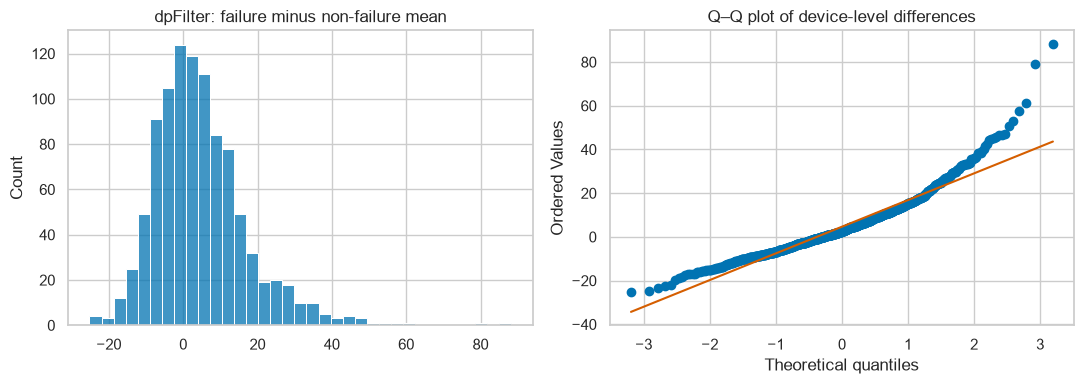

In [48]:
def dpfilter_pairs(frame):
    means = frame.groupby(["unitId", "Failure"])["dpFilter"].mean().unstack()
    means = means.reindex(columns=[0, 1]).dropna()
    return means[1] - means[0]

dp_differences = dpfilter_pairs(hypothesis2_observed)
print("Devices with valid pairs:", len(dp_differences))
display(dp_differences.describe().to_frame("Within-device difference"))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(dp_differences, bins=35, ax=axes[0])
axes[0].set_title("dpFilter: failure minus non-failure mean")
stats.probplot(dp_differences, dist="norm", plot=axes[1])
axes[1].set_title("Q–Q plot of device-level differences")
plt.tight_layout(); plt.show()


**Choice of test:** a paired t-test is equivalent to a one-sample t-test of these differences against zero. It requires independent devices and a sufficiently stable sampling mean. The Q–Q plot reveals tail departures, so a bootstrap interval is also reported. Neither the graph nor the bootstrap establishes independence between devices sharing a depot.

In [49]:
dp_test = stats.ttest_1samp(dp_differences, popmean=0, alternative="greater")
dp_dz = dp_differences.mean() / dp_differences.std(ddof=1)
dp_margin = stats.t.ppf(1 - .025/2, len(dp_differences)-1) * stats.sem(dp_differences)
rng = np.random.default_rng(12)
dp_boot = np.array([rng.choice(dp_differences.to_numpy(), size=len(dp_differences), replace=True).mean() for _ in range(2000)])
print(f"t = {dp_test.statistic:.3f}, p = {dp_test.pvalue:.3e}, dz = {dp_dz:.3f}")
print("97.5% t interval:", dp_differences.mean()-dp_margin, dp_differences.mean()+dp_margin)
print("97.5% bootstrap interval:", np.quantile(dp_boot, [.0125, .9875]))
display(Markdown(f"**Result:** the mean within-device difference is {dp_differences.mean():.3f} across {len(dp_differences)} devices. At alpha = 0.05, we {'reject' if dp_test.pvalue < .05 else 'do not reject'} H0. The standardized effect dz is {dp_dz:.3f}; statistical significance alone does not establish practical usefulness or future predictive ability."))


t = 11.563, p = 2.187e-29, dz = 0.369
97.5% t interval: 3.75748040830796 5.567868337236637
97.5% bootstrap interval: [3.77032805 5.54785933]


**Result:** the mean within-device difference is 4.663 across 984 devices. At alpha = 0.05, we reject H0. The standardized effect dz is 0.369; statistical significance alone does not establish practical usefulness or future predictive ability.

### Joint reporting and interpretation
We show Holm-adjusted p-values for the two primary calculations to account for testing two hypotheses. This does **not** fix the dependence problem in the original row-level hours_service test; that result remains exploratory. Hypothesis 2's device-level design avoids within-device pseudoreplication but still assumes independence between devices.

In [50]:
joint_tests = pd.DataFrame({"Hypothesis": ["H1: hours_service (original row-level test)", "H2: dpFilter (device-level paired test)"],
                            "p": [p_value, dp_test.pvalue]})
joint_tests["Holm p"] = multipletests(joint_tests["p"], method="holm")[1]
display(joint_tests.style.format({"p": "{:.3e}", "Holm p": "{:.3e}"}))


,Hypothesis,p,Holm p
0,H1: hours_service (original row-level test),1.068e-43,2.135e-43
1,H2: dpFilter (device-level paired test),2.187e-29,2.187e-29


## 1.3 B – Statistical power
### Hypothesis 1 – Original teammate's calculations
The following original calculations report a standardized difference, t-test-based row-level power and an approximate balanced-group sample-size calculation at device level. They are preserved as requested.

**Important scope:** these are not direct power calculations for the Mann–Whitney test. The row-based calculation also overcounts dependent observations, and observed-effect power is not an independent confirmation of the result. The balanced device-level calculation concerns devices with any recorded failure versus none, which differs from the original row-level groups. Treat these outputs as approximate design calculations, not proof that the original test has sufficient valid power.

A numerical fallback evaluates the same noncentral-t rejection probability if the library returns NaN for the large sample. This changes numerical evaluation only; it does not resolve the statistical limitations of the row-level model.

In [51]:
# Effect size on rows: Cohen's d (failure vs non-failure rows)
pooled_sd = np.sqrt((g0.var() + g1.var()) / 2)
d_rows = (g1.mean() - g0.mean()) / pooled_sd
print(f"Cohen's d (rows) = {d_rows:.3f}")

# Power at the observed number of rows
power_rows = TTestIndPower().power(
    effect_size=abs(d_rows), nobs1=len(g1), ratio=len(g0) / len(g1), alpha=0.05
)
# Numerical fallback for a noncentral-t implementation returning NaN at large df.
# Same two-sided independent-t power model and parameters, not a different test.
if not np.isfinite(power_rows):
    from scipy.integrate import quad
    df_power = len(g1) + len(g0) - 2
    ncp_power = abs(d_rows) * np.sqrt(len(g1)*len(g0)/(len(g1)+len(g0)))
    crit_power = stats.t.isf(.05/2, df_power)
    scale_power = np.sqrt(2*df_power)
    def rejection_integrand(z):
        v = df_power + scale_power*z
        if v <= 0: return 0.0
        cut = crit_power*np.sqrt(v/df_power)
        return (stats.norm.sf(cut-ncp_power)+stats.norm.cdf(-cut-ncp_power))*stats.chi2.pdf(v,df_power)*scale_power
    power_rows = quad(rejection_integrand, max(-12, -df_power/scale_power), 12, epsabs=1e-10)[0]
print(f"Power (rows, n1={len(g1)}, n0={len(g0)}) = {power_rows:.3f}")

Cohen's d (rows) = 0.338
Power (rows, n1=1842, n0=13815) = 1.000


In [52]:
# One row per machine: hours_service and share of failure rows (used in 6.3 and 6.5)
unit = data.groupby('unitId').agg(
    hours=('hours_service', 'first'),
    fail_rate=('Failure', 'mean')
)


In [53]:
# Unit level: one observation per machine
unit_g0 = unit.loc[unit["fail_rate"] == 0, "hours"]
unit_g1 = unit.loc[unit["fail_rate"] > 0, "hours"]
d_units = (unit_g1.mean() - unit_g0.mean()) / np.sqrt((unit_g0.var() + unit_g1.var()) / 2)

# Machines per group needed for power 0.8 at alpha 0.05
n_needed = TTestIndPower().solve_power(effect_size=abs(d_units), power=0.8, alpha=0.05, ratio=1)
print(f"Cohen's d (units) = {d_units:.3f}")
print(f"Machines per group needed for power 0.8 ≈ {n_needed:.0f} "
      f"(available: {len(unit_g0)} without failures, {len(unit_g1)} with failures)")

Cohen's d (units) = 0.335


Machines per group needed for power 0.8 ≈ 141 (available: 886 without failures, 1114 with failures)


**Conclusion for the original power analysis:** compare the reported available device counts with the approximate sample-size calculation, while retaining the limitations above. A reliable power statement for the original question would need a design that accounts for repeated observations and matches the actual test. The supplied methods have not been replaced.

### Hypothesis 2 – Power of the paired t-test
Here the power model matches the actual test. We use the number of valid device pairs and evaluate specified standardized effects dz = 0.10, 0.20 and 0.30, rather than using observed-effect power as supporting evidence. Alpha = 0.025 is a conservative allowance for two hypotheses. The working target is 80% power for dz = 0.20; practical significance is not established by this choice.

In [54]:
dp_power_model = TTestPower()
dp_power = pd.DataFrame({"Assumed dz": [.10, .20, .30],
    "Power": [dp_power_model.power(effect_size=e, nobs=len(dp_differences), alpha=.025, alternative="larger") for e in [.10, .20, .30]]})
display(dp_power)
dp_needed = int(np.ceil(dp_power_model.solve_power(effect_size=.20, power=.80, alpha=.025, alternative="larger")))
dp_mde = dp_power_model.solve_power(nobs=len(dp_differences), power=.80, alpha=.025, alternative="larger")
display(Markdown(f"**Power conclusion:** {len(dp_differences)} pairs are available; approximately {dp_needed} are required for dz = 0.20 at 80% power under this model. The smallest effect detectable with 80% power is approximately dz = {dp_mde:.3f}. The available sample {'meets' if len(dp_differences) >= dp_needed else 'does not meet'} the chosen target, conditional on the paired-test assumptions."))


,Assumed dz,Power
0,0.1000,0.8798
1,0.2000,1.0000
2,0.3000,1.0000


**Power conclusion:** 984 pairs are available; approximately 199 are required for dz = 0.20 at 80% power under this model. The smallest effect detectable with 80% power is approximately dz = 0.089. The available sample meets the chosen target, conditional on the paired-test assumptions.

## Final summary
Section 1.1 explores the original data. Section 1.2 retains the teammate's cleaning, interpolation and outlier-treatment methods; their assumptions and risks are stated next to the corresponding steps. Hypothesis 1 and its original power calculations are retained with explicit interpretation limits. Hypothesis 2 adds a device-level paired comparison of dpFilter using observed values and matching power calculations.

Sources: the supplied IAU assignment, dataset 012 and Assignment.ipynb. All transformations are recorded above. Before predictive modelling, clarify the timing of service hours and maintenance metadata, define the prediction horizon and fit preprocessing using only information available at prediction time. The current associations do not demonstrate advance prediction of failures.

In [55]:
assert len(readings) == len(raw["readings"]) - 237
assert len(data) == len(hypothesis2_observed)
assert data.Failure.isin([0, 1]).all()
assert dp_differences.index.is_unique
print("Execution checks passed. CSV files were loaded once in the shared setup.")

Execution checks passed. CSV files were loaded once in the shared setup.
